In [1]:
using Oceananigans, CairoMakie
using ColorSchemes
using MPI

┌ Info: Oceananigans will use 8 threads
└ @ Oceananigans /nfs/stak/users/carlipp/.julia/packages/Oceananigans/mLrHQ/src/Oceananigans.jl:137


In [2]:
loc = "/nfs/hpc/share/carlipp/ngpu-scaling/strong/"
ds_1gpu = FieldDataset(loc*"1-gpu_rank0.jld2"; backend = OnDisk())
ds_2gpu = FieldDataset(loc*"2-gpu_rank0.jld2"; backend = OnDisk())
ds_4gpu = FieldDataset(loc*"4-gpu_rank0.jld2"; backend = OnDisk())

FieldDataset with 5 fields and 0 metadata entries:
├── KE: 1×1×1×17 FieldTimeSeries{OnDisk} located at (⋅, ⋅, ⋅) of KE at /nfs/hpc/share/carlipp/ngpu-scaling/strong/4-gpu_rank0.jld2
├── dissipation: 1×1×1×17 FieldTimeSeries{OnDisk} located at (⋅, ⋅, ⋅) of dissipation at /nfs/hpc/share/carlipp/ngpu-scaling/strong/4-gpu_rank0.jld2
├── u: 256×1024×512×17 FieldTimeSeries{OnDisk} located at (Face, Center, Center) of u at /nfs/hpc/share/carlipp/ngpu-scaling/strong/4-gpu_rank0.jld2
├── v: 256×1024×512×17 FieldTimeSeries{OnDisk} located at (Center, Face, Center) of v at /nfs/hpc/share/carlipp/ngpu-scaling/strong/4-gpu_rank0.jld2
└── w: 256×1024×512×17 FieldTimeSeries{OnDisk} located at (Center, Center, Face) of w at /nfs/hpc/share/carlipp/ngpu-scaling/strong/4-gpu_rank0.jld2


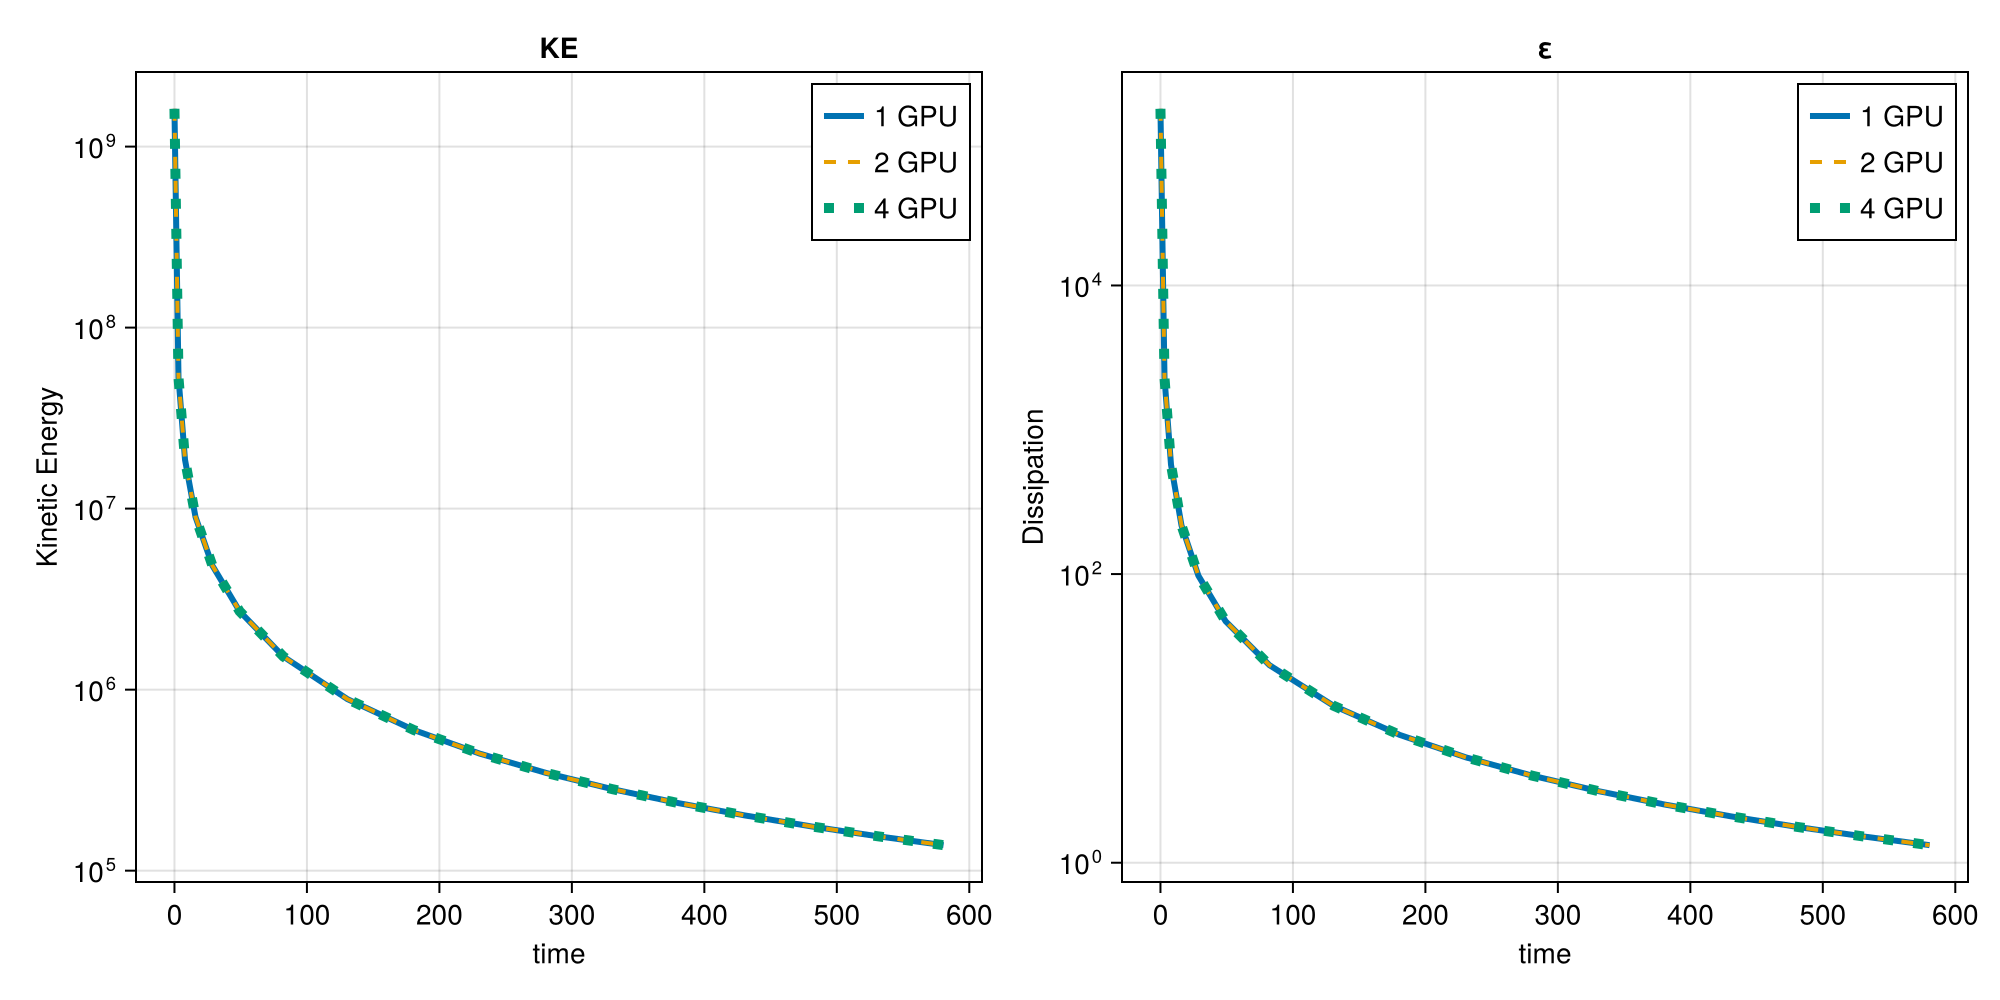

In [3]:
fig = Figure(size = (1000, 500))
ax = Axis(fig[1, 1], yscale = log10, title = "KE", ylabel = "Kinetic Energy", xlabel = "time")
ax2 = Axis(fig[1, 2], yscale = log10, title = "ε", ylabel = "Dissipation", xlabel = "time")
lines!(ax, ds_1gpu.KE, label = "1 GPU", linewidth = 3)
lines!(ax, ds_2gpu.KE, label = "2 GPU", linestyle = :dash, linewidth = 2)
lines!(ax, ds_4gpu.KE, label = "4 GPU", linestyle = :dot, linewidth = 5)
lines!(ax2, ds_1gpu.dissipation, label = "1 GPU", linewidth = 3)
lines!(ax2, ds_2gpu.dissipation, label = "2 GPU", linestyle = :dash, linewidth = 2)
lines!(ax2, ds_4gpu.dissipation, label = "4 GPU", linestyle = :dot, linewidth = 5)
axislegend(ax)
axislegend(ax2)
fig

In [4]:
n = size(ds_1gpu.KE)[end]

17

In [5]:
ke_1 = [collect(ds_1gpu.KE[i])[1] for i = 1:n]
ke_2 = [collect(ds_2gpu.KE[i])[1] for i = 1:n]
ke_4 = [collect(ds_4gpu.KE[i])[1] for i = 1:n];

In [6]:
println(ke_1)
println(ke_2)
println(ke_4)

Float32[1.6168311f9, 5.2878076f7, 1.8625386f7, 8.994792f6, 4.8458255f6, 2.710348f6, 1.5231776f6, 886481.8, 598773.3, 442849.1, 346605.47, 282004.47, 236052.84, 201916.61, 175690.56, 154990.0, 138294.62]
Float32[1.6168311f9, 5.287808f7, 1.8625386f7, 8.994792f6, 4.845825f6, 2.7103475f6, 1.5231778f6, 886482.75, 598774.6, 442850.78, 346606.97, 282005.97, 236053.62, 201916.78, 175691.03, 154991.36, 138296.62]
Float32[1.6168311f9, 5.287807f7, 1.8625384f7, 8.99479f6, 4.8458235f6, 2.7103452f6, 1.5231765f6, 886481.2, 598771.94, 442846.38, 346601.44, 282000.4, 236049.42, 201915.1, 175691.14, 154992.8, 138299.89]


In [7]:
isapprox(ke_1, ke_2, rtol = 1e-5)

true

In [8]:
isapprox(ke_2, ke_4, rtol = 1e-5)

true

In [9]:
u1 = FieldTimeSeries(loc*"1-gpu", "u"; backend = OnDisk())
u2 = FieldTimeSeries(loc*"2-gpu", "u"; backend = OnDisk())
u4 = FieldTimeSeries(loc*"4-gpu", "u"; backend = OnDisk());

In [10]:
u1slice = interior(u1[end])[:, :, 10]
u2slice = interior(u2[end])[:, :, 10]
u4slice = interior(u4[end])[:, :, 10];

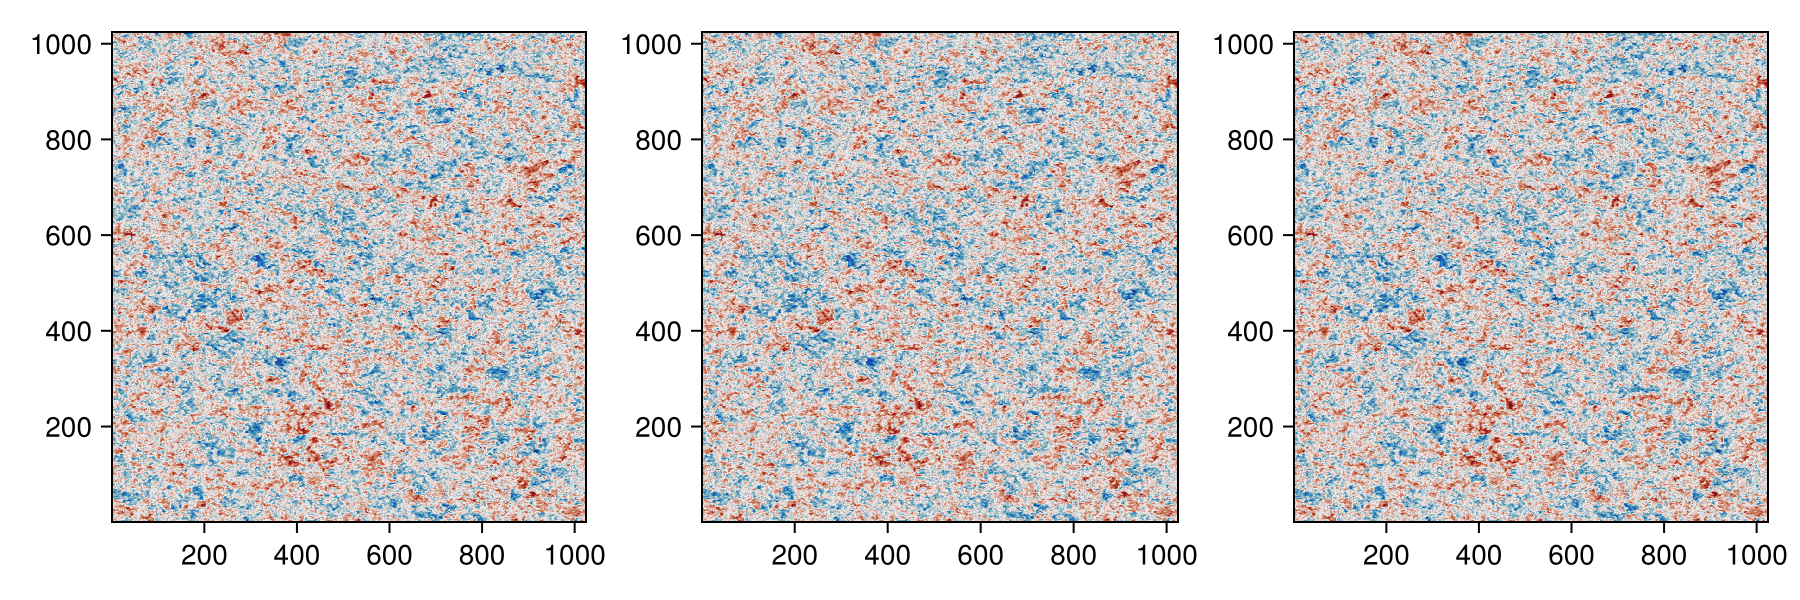

In [11]:
fig = Figure(size = (900, 300))
ax1 = Axis(fig[1, 1])
ax2 = Axis(fig[1, 2])
ax3 = Axis(fig[1, 3])
heatmap!(ax1, u1slice, colormap = :balance)
heatmap!(ax2, u2slice, colormap = :balance)
heatmap!(ax3, u4slice, colormap = :balance)
fig

In [14]:
u1_end = interior(u1[end])
u2_end = interior(u2[end])
u4_end = interior(u4[end]);

In [15]:
using Statistics

println(std(u1_end))
println(std(u2_end))
println(std(u4_end))
println(std(u1_end-u2_end))
println(std(u1_end-u4_end))

0.018848631701377613
0.01884833788913949
0.018848691000970683
0.0017811109386798674
0.004314929220661709
